# pT spectrum: unbiased vs biased

Plots the output of `startBasis.C` (see `BIAS.md`): `tRef` (unbiased, X + Y) and `tBiased` (X downsampled + Y′), with the measured biased/unbiased ratio and the expected one.
Same style as the other matplotlib plots (`plot_mpl.py`). Run from `AnalysisCode/`; inputs are read from `../Output/files/`, plots are saved next to the other matplotlib plots, in `../Output/plots/mpl/<bias>/<sample>/pt<lo>-<hi>/pt_bias_vs_expected.pdf`.

In [1]:
import numpy as np
import uproot
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

import plot_mpl as pm   # shared style and helpers

pm.use_tex_if_available()

True

In [2]:
# --- EDIT ---
TAG = "10M"   # sample tag = UNBIAS_TAG used for driveBins.C (e.g. 10M, 50K)
PT_MIN, PT_MAX = 100.0, 140.0
NBINS = 20
FILES_DIR = "../Output/files"
PLOT_DIR = "../Output/plots/mpl"
P, D = 8.0, 0.1   # power-law bias parameters (as in driveBins.C)

In [3]:
def w_bias(pt, lo, hi, p, d):
    """Probability to keep an X jet, as in startBasis.C."""
    pt = np.asarray(pt, dtype=float)
    return (lo**p - d * hi**p + (d - 1) * pt**p) / (lo**p - hi**p)


def read(path, edges):
    """Unbiased and biased pT histograms, and the X-jet pT values, from a startBasis file."""
    with uproot.open(path) as f:
        arr = {n: f[n].arrays(["pt_raw", "weight"], library="np") for n in ("tX", "tRef", "tBiased")}
    h_ref = pm.Hist.fill(arr["tRef"]["pt_raw"], arr["tRef"]["weight"], edges)
    h_bia = pm.Hist.fill(arr["tBiased"]["pt_raw"], arr["tBiased"]["weight"], edges)
    return h_ref, h_bia, arr["tX"]["pt_raw"]


def plot_bias(h_ref, h_bia, x, expected, params, out_dir):
    """Unbiased and biased spectra, and biased/unbiased ratio with the expected curve."""
    fig, ax, axr = pm.ratio_figure()
    pm.draw_hist(ax, h_ref, pm.C_REF, label="Unbiased")
    pm.draw_hist(ax, h_bia, pm.C_BIASED, label="Biased")
    ax.set_yscale("log")
    pos = np.concatenate([h_ref.values, h_bia.values])
    pos = pos[pos > 0]
    ax.set_ylim(0.5 * pos.min(), 10 * pos.max())
    ax.set_ylabel("Weighted entries")
    ax.legend(loc="upper right")
    ax.text(0.04, 0.94, pm.bin_label(PT_MIN, PT_MAX) + "\n" + params, transform=ax.transAxes, va="top")

    pm.draw_ratio(axr, h_bia.divide(h_ref), pm.C_BIASED)
    axr.plot(x, expected, color="black", lw=1.2, ls="--")
    axr.axhline(1.0, color="gray", ls=":", lw=0.8)
    axr.set_xlim(PT_MIN, PT_MAX)
    axr.set_xlabel(r"$p_{\mathrm{T}}$ [GeV]")
    axr.set_ylabel("Biased / unbiased")
    axr.legend([Line2D([], [], color=pm.C_BIASED, lw=1.4), Line2D([], [], color="black", lw=1.2, ls="--")],
               ["Measured", "Expected"], loc="lower left", ncol=2)

    import os
    os.makedirs(out_dir, exist_ok=True)
    path = os.path.join(out_dir, "pt_bias_vs_expected.pdf")
    fig.savefig(path, bbox_inches="tight")
    print("wrote", path)
    plt.show()


edges = np.linspace(PT_MIN, PT_MAX, NBINS + 1)
x = np.linspace(PT_MIN, PT_MAX, 300)

## Power-law bias

wrote ../Output/plots/mpl/powerlaw/10M/pt100-140/pt_bias_vs_expected.pdf


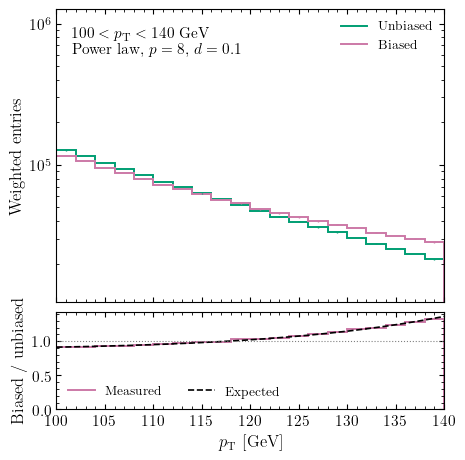

In [4]:
h_ref, h_bia, pt_x = read(f"{FILES_DIR}/startBasis_{PT_MIN:g}_{PT_MAX:g}_{TAG}.root", edges)

# expected ratio: (w_bias(pT) + 2 - k) / 2, k = <w_bias> over X jets
k = w_bias(pt_x, PT_MIN, PT_MAX, P, D).mean()
expected = (w_bias(x, PT_MIN, PT_MAX, P, D) + 2 - k) / 2

plot_bias(h_ref, h_bia, x, expected, rf"Power law, $p = {P:g}$, $d = {D:g}$",
          pm.out_dir(PLOT_DIR, TAG, PT_MIN, PT_MAX))

## Log-normal bias

Output of `startBasis.C` run with `biasType=1` (see `BIAS.md`). The X keep probability is the log-normal $\bar D(p_T)$ divided by its peak value.

In [5]:
# --- EDIT (must match the startBasis run with biasType=1, see driveBinsLognormal.C) ---
LN_MU, LN_SIGMA = 4.733, 0.12
LN_NORM = 1.0   # amplitude of w (maximum keep probability); 1 = strongest bias


def lognormal_pdf(pt, mu, sigma):
    """Log-normal D(pt) = exp[-(ln pt - mu)^2 / (2 sigma^2)] / (sqrt(2 pi) sigma pt)."""
    pt = np.asarray(pt, dtype=float)
    return np.exp(-(np.log(pt) - mu) ** 2 / (2 * sigma**2)) / (np.sqrt(2 * np.pi) * sigma * pt)


def w_lognormal(pt, mu, sigma, norm=LN_NORM):
    """Keep probability as in lognormalBiasWeight(): norm * D(pt) / D(mode), mode = exp(mu - sigma^2), capped at 1."""
    w = norm * lognormal_pdf(pt, mu, sigma) / lognormal_pdf(np.exp(mu - sigma**2), mu, sigma)
    return np.minimum(w, 1.0)

wrote ../Output/plots/mpl/lognormal/10M/pt100-140/pt_bias_vs_expected.pdf


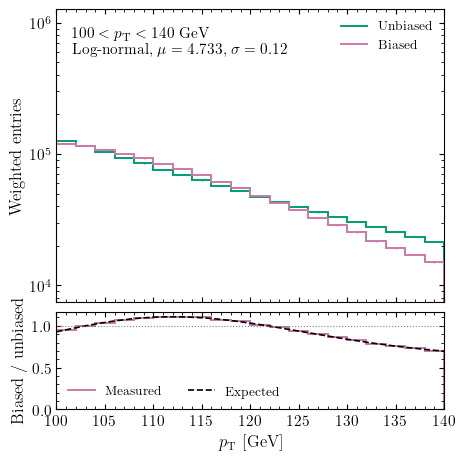

In [6]:
h_ref, h_bia, pt_x = read(f"{FILES_DIR}/startBasis_{PT_MIN:g}_{PT_MAX:g}_lognormal_{TAG}.root", edges)

# expected ratio: (w(pT) + 2 - k) / 2, k = <w> over X jets
k = w_lognormal(pt_x, LN_MU, LN_SIGMA).mean()
expected = (w_lognormal(x, LN_MU, LN_SIGMA) + 2 - k) / 2

plot_bias(h_ref, h_bia, x, expected, rf"Log-normal, $\mu = {LN_MU:g}$, $\sigma = {LN_SIGMA:g}$",
          pm.out_dir(PLOT_DIR, f"lognormal_{TAG}", PT_MIN, PT_MAX))